## 1. Import Libraries

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
np.random.seed(42); tf.random.set_seed(42)

## 2. Load the Dataset

In [2]:
ipl = pd.read_csv('ipl_data.csv')
print(ipl.shape)
ipl.head()

(76014, 15)


,mid,date,venue,bat_team,bowl_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
0,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,P Kumar,1,0,0.1,1,0,0,0,222
1,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,1,0,0.2,1,0,0,0,222
2,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.2,2,0,0,0,222
3,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.3,2,0,0,0,222
4,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.4,2,0,0,0,222


In [3]:
ipl.info()
print('Missing values:', ipl.isna().sum().sum())
ipl.describe()

<class 'pandas.DataFrame'>
RangeIndex: 76014 entries, 0 to 76013
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mid             76014 non-null  int64  
 1   date            76014 non-null  str    
 2   venue           76014 non-null  str    
 3   bat_team        76014 non-null  str    
 4   bowl_team       76014 non-null  str    
 5   batsman         76014 non-null  str    
 6   bowler          76014 non-null  str    
 7   runs            76014 non-null  int64  
 8   wickets         76014 non-null  int64  
 9   overs           76014 non-null  float64
 10  runs_last_5     76014 non-null  int64  
 11  wickets_last_5  76014 non-null  int64  
 12  striker         76014 non-null  int64  
 13  non-striker     76014 non-null  int64  
 14  total           76014 non-null  int64  
dtypes: float64(1), int64(8), str(6)
memory usage: 8.7 MB
Missing values: 0


,mid,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
count,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000
mean,308.627740,74.889349,2.415844,9.783068,33.216434,1.120307,24.962283,8.869287,160.901452
std,178.156878,48.823327,2.015207,5.772587,14.914174,1.053343,20.079752,10.795742,29.246231
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67.000000
25%,154.000000,34.000000,1.000000,4.600000,24.000000,0.000000,10.000000,1.000000,142.000000
50%,308.000000,70.000000,2.000000,9.600000,34.000000,1.000000,20.000000,5.000000,162.000000
75%,463.000000,111.000000,4.000000,14.600000,43.000000,2.000000,35.000000,13.000000,181.000000
max,617.000000,263.000000,10.000000,19.600000,113.000000,7.000000,175.000000,109.000000,263.000000


## 3. Exploratory Data Analysis

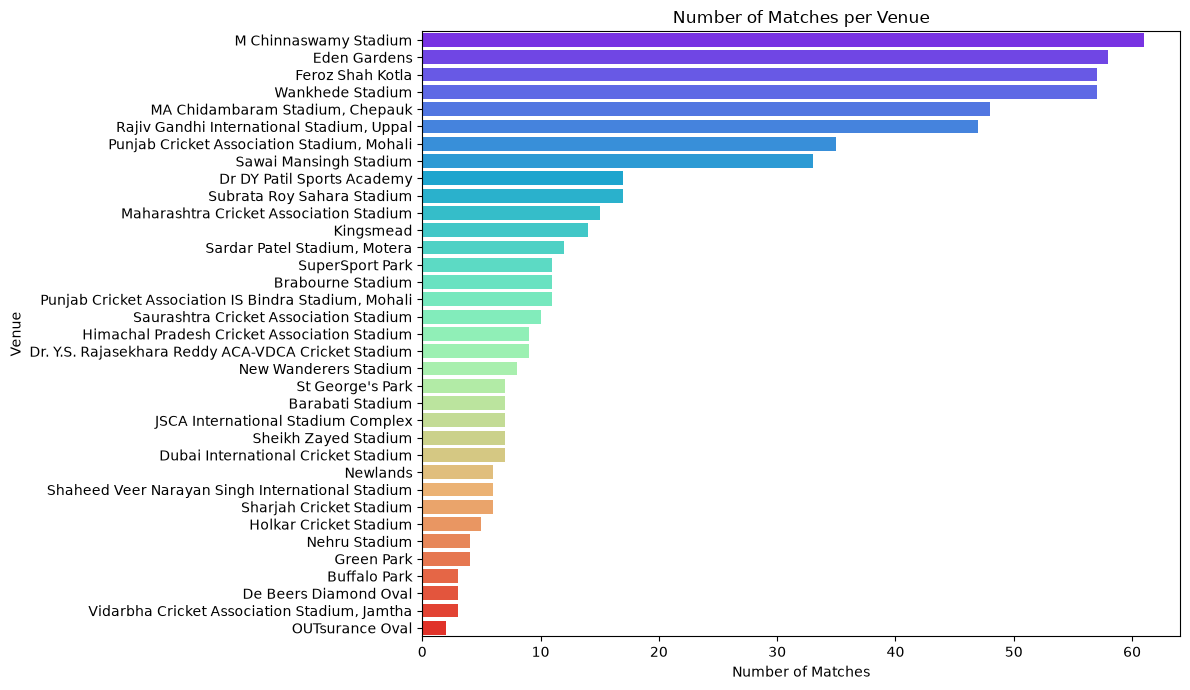

In [4]:
data = ipl.copy()
matches_count = data[['mid','venue']].drop_duplicates()['venue'].value_counts()
plt.figure(figsize=(12,7))
sns.barplot(x=matches_count.values, y=matches_count.index, hue=matches_count.index, palette='rainbow', legend=False)
plt.title('Number of Matches per Venue'); plt.xlabel('Number of Matches'); plt.ylabel('Venue')
plt.tight_layout(); plt.show()

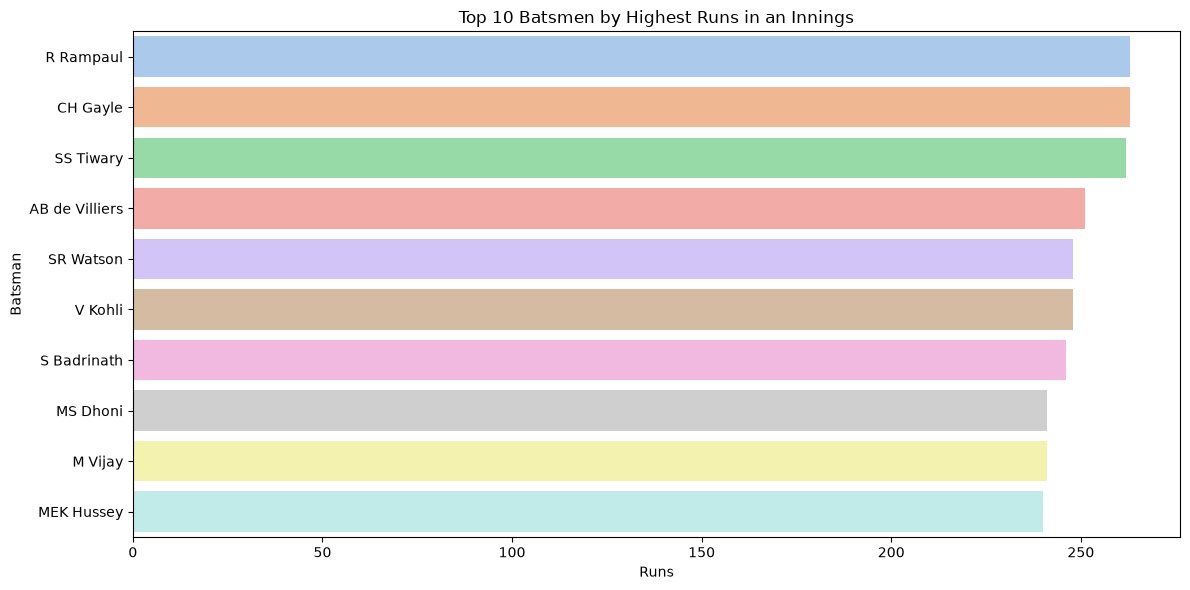

In [5]:
runs_by_batsman = data.groupby('batsman')['runs'].max().sort_values(ascending=False).head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=runs_by_batsman.values, y=runs_by_batsman.index, hue=runs_by_batsman.index, palette='pastel', legend=False)
plt.title('Top 10 Batsmen by Highest Runs in an Innings'); plt.xlabel('Runs'); plt.ylabel('Batsman')
plt.tight_layout(); plt.show()

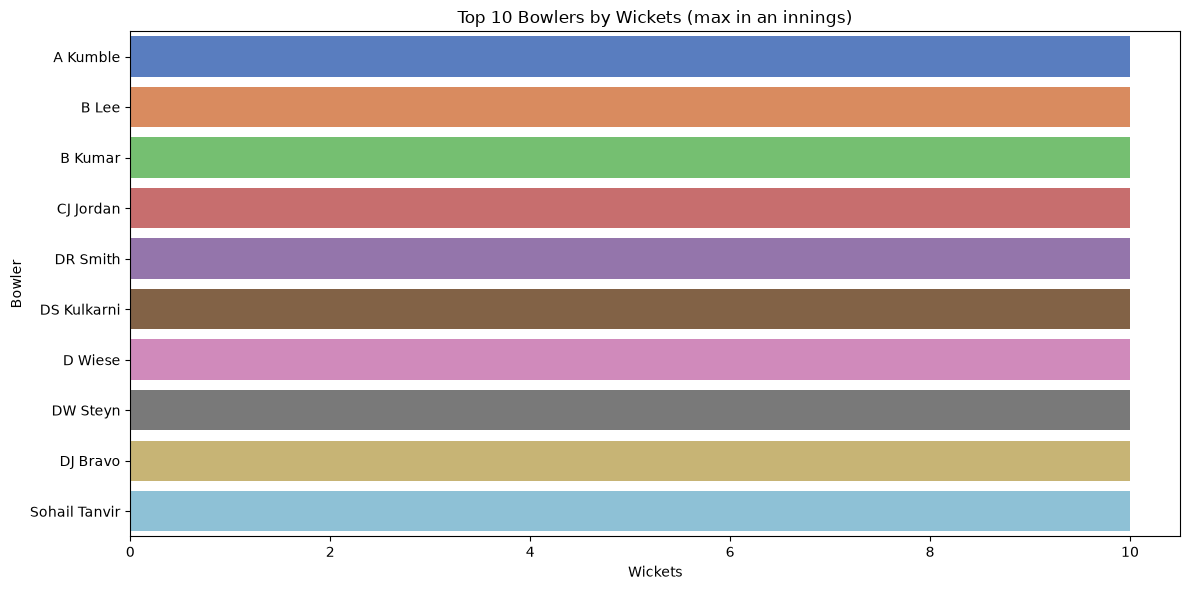

In [6]:
wickets_by_bowler = data.groupby('bowler')['wickets'].max().sort_values(ascending=False).head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=wickets_by_bowler.values, y=wickets_by_bowler.index, hue=wickets_by_bowler.index, palette='muted', legend=False)
plt.title('Top 10 Bowlers by Wickets (max in an innings)'); plt.xlabel('Wickets'); plt.ylabel('Bowler')
plt.tight_layout(); plt.show()

## 4. Label Encoding
Neural networks need numbers, so the categorical columns are converted to integer labels. The encoders are stored so we can reuse them at prediction time.

In [7]:
cat_cols = ['bat_team','bowl_team','venue','batsman','bowler']
data_encoded = data.copy()
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    data_encoded[col] = le.fit_transform(data_encoded[col])
    label_encoders[col] = le
data_encoded.head()

,mid,date,venue,bat_team,bowl_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
0,1,2008-04-18,14,6,12,328,201,1,0,0.1,1,0,0,0,222
1,1,2008-04-18,14,6,12,61,201,1,0,0.2,1,0,0,0,222
2,1,2008-04-18,14,6,12,61,201,2,0,0.2,2,0,0,0,222
3,1,2008-04-18,14,6,12,61,201,2,0,0.3,2,0,0,0,222
4,1,2008-04-18,14,6,12,61,201,2,0,0.4,2,0,0,0,222


## 5. Feature Selection
`date` and `mid` are identifiers, so they are dropped before computing correlations.

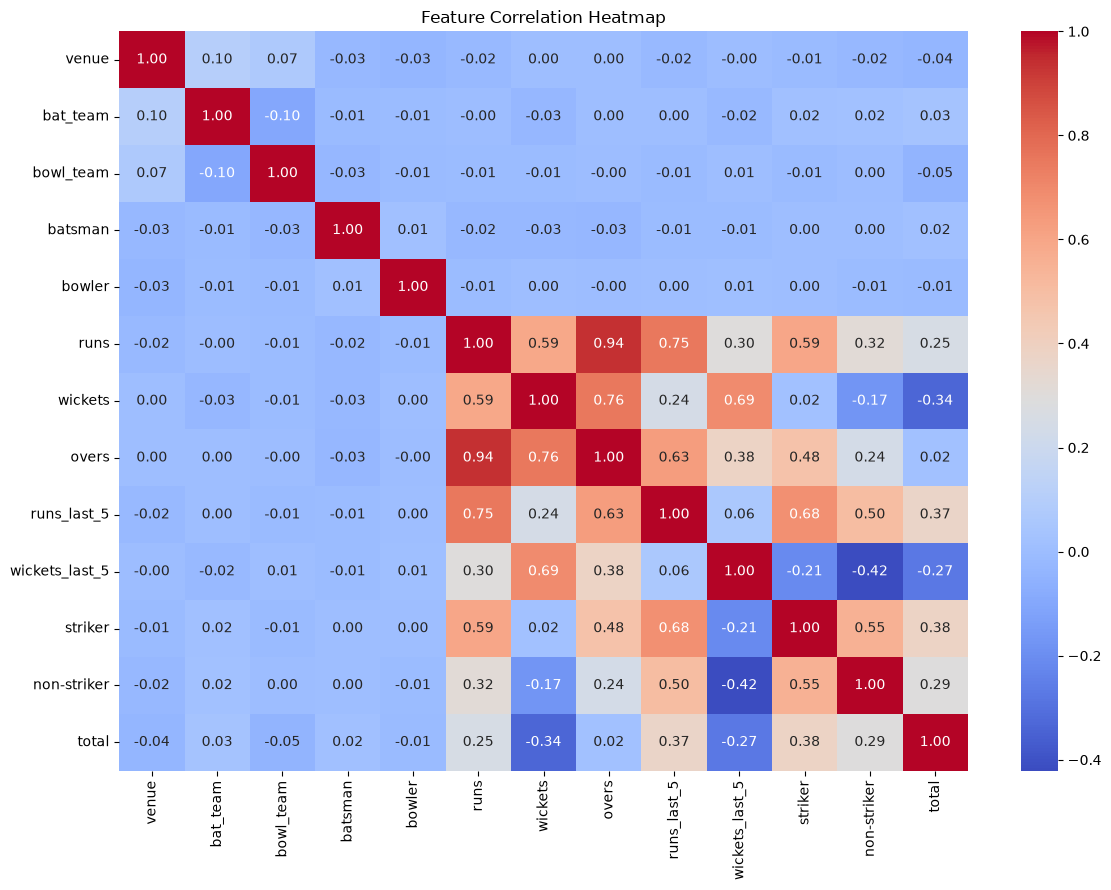

In [8]:
data_corr = data_encoded.drop(columns=['date','mid'])
plt.figure(figsize=(12,9))
sns.heatmap(data_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap'); plt.tight_layout(); plt.show()

`runs_last_5`, `wickets_last_5` and `non-striker` are highly correlated with other features (redundant), so they are excluded from the model.

## 6. Train / Test Split

In [9]:
feature_cols = ['bat_team','bowl_team','venue','runs','wickets','overs','striker','batsman','bowler']
X = data_encoded[feature_cols]
y = data_encoded['total']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

(53209, 9) (22805, 9)


## 7. Feature Scaling (Min-Max)

In [10]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled  = scaler.transform(X_test)

## 8. Build the Neural Network
Two hidden ReLU layers (512 and 216 units) and a linear output neuron for regression. Huber loss is used because it is robust to outliers.

In [11]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(512, activation='relu'),
    keras.layers.Dense(216, activation='relu'),
    keras.layers.Dense(1, activation='linear')
])
model.compile(optimizer='adam', loss=keras.losses.Huber(delta=1.0))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │           5,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 216)                 │         110,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             217 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 116,145 (453.69 KB)

 Trainable params: 116,145 (453.69 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train the Model

In [12]:
history = model.fit(X_train_scaled, y_train, epochs=10, batch_size=64,
                    validation_data=(X_test_scaled, y_test), verbose=2)

Epoch 1/10
832/832 - 2s - 2ms/step - loss: 26.2296 - val_loss: 14.7630
Epoch 2/10
832/832 - 1s - 1ms/step - loss: 14.8681 - val_loss: 14.3634
Epoch 3/10
832/832 - 1s - 1ms/step - loss: 14.6946 - val_loss: 14.2588
Epoch 4/10
832/832 - 1s - 1ms/step - loss: 14.5669 - val_loss: 14.1230
Epoch 5/10
832/832 - 1s - 2ms/step - loss: 14.4573 - val_loss: 14.0133
Epoch 6/10
832/832 - 1s - 1ms/step - loss: 14.3675 - val_loss: 13.9447
Epoch 7/10
832/832 - 1s - 1ms/step - loss: 14.3029 - val_loss: 13.8828
Epoch 8/10
832/832 - 1s - 1ms/step - loss: 14.2559 - val_loss: 13.8426
Epoch 9/10
832/832 - 1s - 2ms/step - loss: 14.2213 - val_loss: 13.8173
Epoch 10/10
832/832 - 1s - 2ms/step - loss: 14.1910 - val_loss: 13.7952


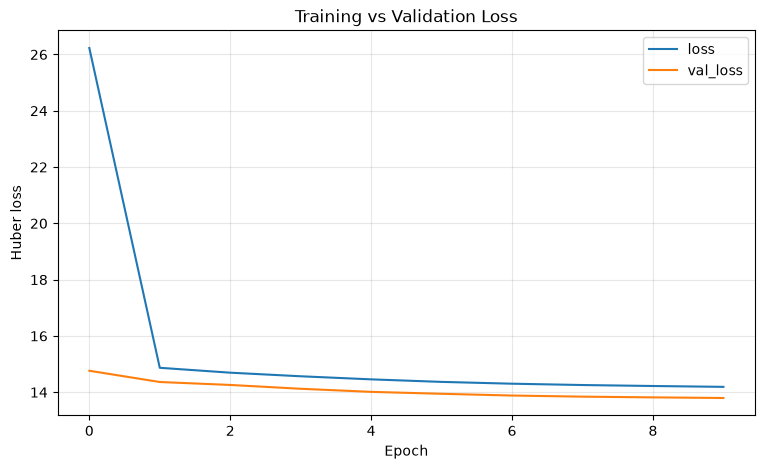

In [13]:
pd.DataFrame(history.history).plot(figsize=(9,5), title='Training vs Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Huber loss'); plt.grid(alpha=.3); plt.show()

## 10. Evaluate the Model

In [14]:
predictions = model.predict(X_test_scaled, verbose=0).ravel()
mae  = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2   = r2_score(y_test, predictions)
print(f'MAE : {mae:.2f} runs')
print(f'RMSE: {rmse:.2f} runs')
print(f'R2  : {r2:.3f}')

MAE : 14.29 runs
RMSE: 19.68 runs
R2  : 0.541


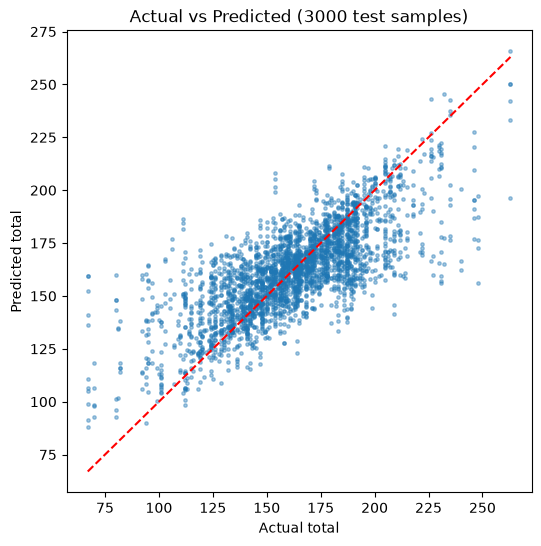

In [15]:
plt.figure(figsize=(6,6))
plt.scatter(y_test.iloc[:3000], predictions[:3000], s=6, alpha=.4)
lims=[y_test.min(), y_test.max()]; plt.plot(lims, lims, 'r--')
plt.xlabel('Actual total'); plt.ylabel('Predicted total'); plt.title('Actual vs Predicted (3000 test samples)')
plt.show()

## 11. Predict a Score
A reusable function that takes a match situation, encodes and scales it exactly like the training data and returns the predicted total.

In [16]:
def predict_score(venue, bat_team, bowl_team, batsman, bowler, runs, wickets, overs, striker=0):
    feats = [
        label_encoders['bat_team'].transform([bat_team])[0],
        label_encoders['bowl_team'].transform([bowl_team])[0],
        label_encoders['venue'].transform([venue])[0],
        runs, wickets, overs, striker,
        label_encoders['batsman'].transform([batsman])[0],
        label_encoders['bowler'].transform([bowler])[0],
    ]
    arr = scaler.transform(pd.DataFrame([feats], columns=feature_cols))
    return int(model.predict(arr, verbose=0)[0][0])

# Example: CSK vs RCB at Chinnaswamy, 10 overs in, 80/2
print('Predicted total:', predict_score(
    venue='M Chinnaswamy Stadium', bat_team='Chennai Super Kings',
    bowl_team='Royal Challengers Bangalore', batsman='MS Dhoni', bowler='P Kumar',
    runs=80, wickets=2, overs=10.0))

Predicted total: 168


### Interactive widget (run in Jupyter / Colab)

In [17]:
import ipywidgets as widgets
from IPython.display import display, clear_output

dd = lambda col, desc: widgets.Dropdown(options=list(label_encoders[col].classes_), description=desc, style={'description_width':'initial'})
w_venue, w_bat, w_bowl = dd('venue','Venue:'), dd('bat_team','Batting Team:'), dd('bowl_team','Bowling Team:')
w_striker, w_bowler = dd('batsman','Striker:'), dd('bowler','Bowler:')
w_runs    = widgets.IntText(value=0, description='Runs:')
w_wickets = widgets.IntText(value=0, description='Wickets:')
w_overs   = widgets.FloatText(value=0.1, description='Overs:')
btn, out = widgets.Button(description='Predict Score'), widgets.Output()

def on_click(_):
    with out:
        clear_output()
        s = predict_score(w_venue.value, w_bat.value, w_bowl.value, w_striker.value,
                          w_bowler.value, w_runs.value, w_wickets.value, w_overs.value)
        print(f'Predicted Total Runs: {s}')
btn.on_click(on_click)
display(w_venue, w_bat, w_bowl, w_striker, w_bowler, w_runs, w_wickets, w_overs, btn, out)

Dropdown(description='Venue:', options=('Barabati Stadium', 'Brabourne Stadium', 'Buffalo Park', 'De Beers Dia…

Dropdown(description='Batting Team:', options=('Chennai Super Kings', 'Deccan Chargers', 'Delhi Daredevils', '…

Dropdown(description='Bowling Team:', options=('Chennai Super Kings', 'Deccan Chargers', 'Delhi Daredevils', '…

Dropdown(description='Striker:', options=('A Ashish Reddy', 'A Chandila', 'A Chopra', 'A Choudhary', 'A Flinto…

Dropdown(description='Bowler:', options=('A Ashish Reddy', 'A Chandila', 'A Choudhary', 'A Flintoff', 'A Kumbl…

IntText(value=0, description='Runs:')

IntText(value=0, description='Wickets:')

FloatText(value=0.1, description='Overs:')

Button(description='Predict Score', style=ButtonStyle())

Output()

## 12. Conclusion
- A feed-forward neural network predicts the final innings total from the in-match state.
- Performance is reported as MAE / RMSE / R² on a held-out 30% test set.
- **Limitations:** the dataset covers 2008–2017 only; rows from the same match appear in both train and test sets (ball-by-ball snapshots), which makes the test score optimistic; and label-encoded players/venues imply a false ordering.
- **Improvements:** split by match (`mid`) instead of by row, one-hot / embedding layers for categorical features, add `runs_last_5`, tune depth and epochs, try dropout and early stopping.